## Simple MultiAgent Architecture

In [1]:
import os
from typing import TypedDict, Annotated, List, Literal
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langchain_core.tools import tool
from langchain_tavily import TavilySearch
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langchain_groq import ChatGroq

llm=ChatGroq(model="openai/gpt-oss-120b")

In [3]:
## Define the state
class AgentState(MessagesState):
    next_agent:str #which agent should go next 

In [4]:
# Create simple tools
@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    # Using Tavily for web search
    search = TavilySearch(max_results=3)
    results = search.invoke(query)
    return str(results)

@tool
def write_summary(content: str) -> str:
    """Write a summary of the provided content."""
    # Simple summary generation
    summary = f"Summary of findings:\n\n{content[:500]}..."
    return summary

In [5]:
# Define agent functions 
def researcher_agent(state: AgentState):
    """Researcher agent that searches for information"""
    
    messages = state["messages"]
    
    # Add system message for context
    system_msg = SystemMessage(content="You are a research assistant. Use the search_web tool to find information about the user's request.")
    
    # Call LLM with tools
    researcher_llm = llm.bind_tools([search_web])
    response = researcher_llm.invoke([system_msg] + messages)
    
    # Return the response and route to writer
    return {
        "messages": [response],
        "next_agent": "writer"
    }

In [6]:
def writer_agent(state: AgentState):
    """Writer agent that creates summaries"""
    
    messages = state["messages"]
    
    # Add system message
    system_msg = SystemMessage(content="You are a technical writer. Review the conversation and create a clear, concise summary of the findings.")
    
    # Simple completion without tools
    response = llm.invoke([system_msg] + messages)
    
    return {
        "messages": [response],
        "next_agent": "end"
    }

In [7]:
# Tool executor node
def execute_tools(state: AgentState):
    """Execute any pending tool calls"""
    messages = state["messages"]
    last_message = messages[-1]
    
    # Check if there are tool calls to execute
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        # Create tool node and execute
        tool_node = ToolNode([search_web])
        response = tool_node.invoke(state)
        return response
    
    # No tools to execute
    return state

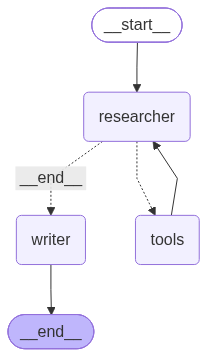

In [8]:
# Build graph
from langgraph.prebuilt import tools_condition

workflow = StateGraph(AgentState)

# Add nodes
workflow.add_node("researcher", researcher_agent)
workflow.add_node("writer", writer_agent)
workflow.add_node("tools", execute_tools)

# Define flow
workflow.set_entry_point("researcher")
workflow.add_conditional_edges("researcher", tools_condition, {"tools": "tools", END: "writer"})
workflow.add_edge("tools", "researcher")
workflow.add_edge("writer", END)
final_workflow=workflow.compile()

final_workflow

In [9]:
response=final_workflow.invoke({"messages":"Reasearch about the usecase of agentic ai in business"})
response["messages"][-1].content

'**Agentic AI\u202f–\u202fBusiness Use‑Case Summary**\n\n| **What it is** | AI agents that can *perceive*, *reason* and *act* autonomously (e.g., call APIs, update databases, send messages) without continual human prompting. An *agentic layer* coordinates many specialized agents toward a shared business goal. |\n|---|---|\n\n---\n\n## 1. Cross‑Industry Use‑Cases (synthesized from MIT Sloan, Hyland, Infor, Bain, TrueFoundry, etc.)\n\n| Industry | Representative Use‑Case | How the Agent Works | Business Value |\n|----------|--------------------------|---------------------|----------------|\n| **Banking & Finance** | Fraud detection & remediation; KYC/onboarding | Real‑time data ingest → risk model → automated hold or request for verification via core‑banking APIs | Faster fraud containment, lower false‑positives, onboarding minutes vs. days |\n| **Retail & E‑commerce** | Personal shopping assistants; dynamic pricing & inventory replenishment | Conversational UI → product‑search API → che